In [30]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

url = "https://dummyjson.com/users?limit=100"
resposta = requests.get(url)
dados_json = resposta.json()

# Cria o DataFrame com todos os dados
df_completo = pd.DataFrame(
    dados_json['users']
)

# Selecionando apenas 9 colunas interessantes para análise
colunas = [
'firstName', 'age', 'bloodGroup',
'height', 'weight', 'eyeColor', 'role', 'university', 'birthDate'
]
df = df_completo[colunas]

print(df.columns.to_list())

['firstName', 'age', 'bloodGroup', 'height', 'weight', 'eyeColor', 'role', 'university', 'birthDate']


In [ ]:
# TRATAMENTO
df['birthDate'] = pd.to_datetime(
    df['birthDate'],
    format="%Y-%m-%d"
)

QUESTÃO 1

INFORMAÇÕES DA TABELA
bloodGroup
O-     19
A+     15
AB-    13
AB+    13
B+     12
B-     10
O+     10
A-      8
dtype: int64


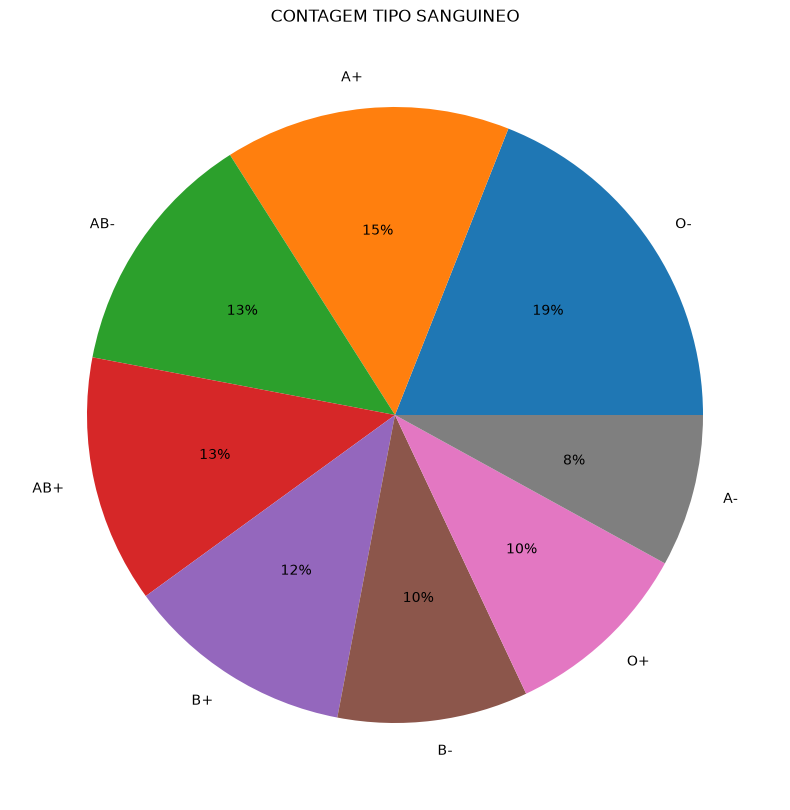

In [29]:
print("INFORMAÇÕES DA TABELA")

contagem_sanguinea = df_completo.groupby(['bloodGroup']).size().sort_values(ascending=False)
print(contagem_sanguinea)

plt.figure(figsize=(10,10))

plt.pie(
    contagem_sanguinea,
    labels=contagem_sanguinea.index,
    autopct='%1.0f%%'
)
plt.title("CONTAGEM TIPO SANGUINEO")

plt.show()


QUESTÃO 2

faixa_etaria
30 ou mais    66
jovem         34
dtype: int64


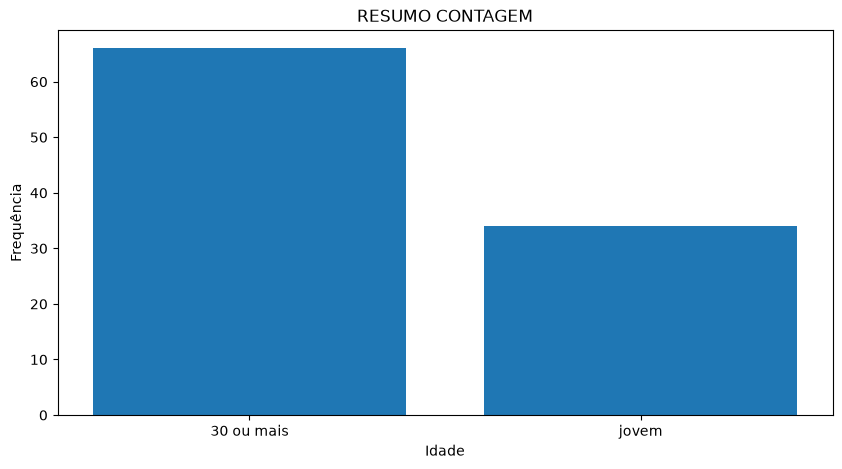

In [68]:
df_completo["faixa_etaria"] = np.where(
    df_completo["age"] < 30,
    "jovem", # se True
    "30 ou mais" # se False
)

resumo_contagem = df_completo.groupby(['faixa_etaria']).size()
print(resumo_contagem)

plt.figure(figsize=(10,5))

plt.bar(
    resumo_contagem.index,
    resumo_contagem.values,
)
plt.title("RESUMO CONTAGEM")
plt.xlabel("Idade")
plt.ylabel("Frequência")
plt.show()


QUESTÃO 3

CONTAGEM DE TODOS OS TIPOS
eyeColor
Brown     18
Hazel     16
Gray      14
Blue      12
Red       12
Green     11
Amber     10
Violet     7
dtype: int64


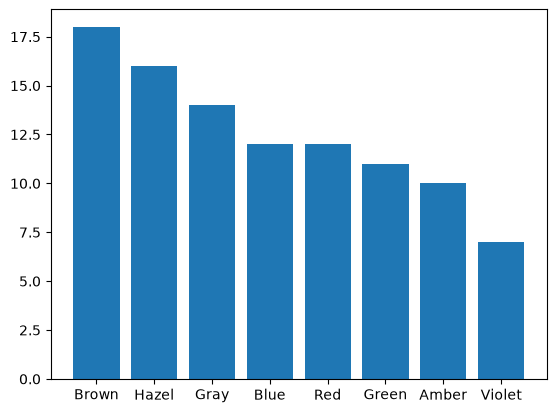

In [66]:
# FILTRAGEM

contagem_olhos = df_completo.groupby(['eyeColor']).size().sort_values(ascending=False)
print("CONTAGEM DE TODOS OS TIPOS")
print(contagem_olhos)

array = np.array(contagem_olhos)

plt.bar(
    contagem_olhos.index,
    contagem_olhos.values,
)
plt.show()

QUESTÃO 4


firstName  height  weight
Aaliyah    164.50  92.03     1
Abigail    186.39  74.61     1
Addison    179.32  76.93     1
Alexander  153.89  77.42     1
Aria       161.81  97.12     1
                            ..
Sophia     177.72  52.60     1
Stella     171.20  81.45     1
Victoria   172.55  97.24     1
William    173.21  82.41     1
Zoe        177.34  56.28     1
Length: 100, dtype: int64


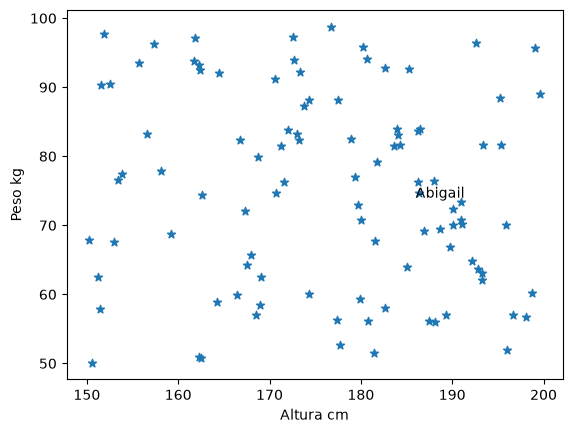

In [84]:
peso_altura = df_completo.groupby(["firstName", 'height', 'weight']).size().sort_values()

print(peso_altura)
# Abigail    186.39  74.61

plt.scatter(
    df_completo['height'],
    df_completo['weight'],
    marker='*',
)

plt.text(186,74, "Abigail")

plt.ylabel("Peso kg")
plt.xlabel("Altura cm")

plt.show()